<a href="https://colab.research.google.com/github/aditya01-dev/Natural-Language-Processing-Lab/blob/main/NLP_Practical_21_Information_Retrieval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TF-IDF MATRIX SHAPE: (10, 43)

RANKED DOCUMENTS:


,Rank,Document_ID,Document,Similarity_Score
0,1,Document 5,Artificial intelligence is used in robotics an...,0.477880
1,2,Document 10,Robotics uses artificial intelligence to autom...,0.366539
2,3,Document 6,Python is widely used for data science and mac...,0.266744
3,4,Document 1,Machine learning enables computers to learn pa...,0.266744
4,5,Document 9,Data science combines statistics programming a...,0.259507
5,6,Document 2,Deep learning uses neural networks for complex...,0.187402
6,7,Document 7,Neural networks are important in deep learning...,0.111642
7,8,Document 4,Computer vision enables machines to recognize ...,0.000000
8,9,Document 3,Natural language processing helps computers un...,0.000000
9,10,Document 8,Text processing is an important task in natura...,0.000000



RETRIEVED DOCUMENTS:


,Rank,Document_ID,Document,Similarity_Score
0,1,Document 5,Artificial intelligence is used in robotics an...,0.477880
1,2,Document 10,Robotics uses artificial intelligence to autom...,0.366539
2,3,Document 6,Python is widely used for data science and mac...,0.266744
3,4,Document 1,Machine learning enables computers to learn pa...,0.266744
4,5,Document 9,Data science combines statistics programming a...,0.259507
5,6,Document 2,Deep learning uses neural networks for complex...,0.187402
6,7,Document 7,Neural networks are important in deep learning...,0.111642


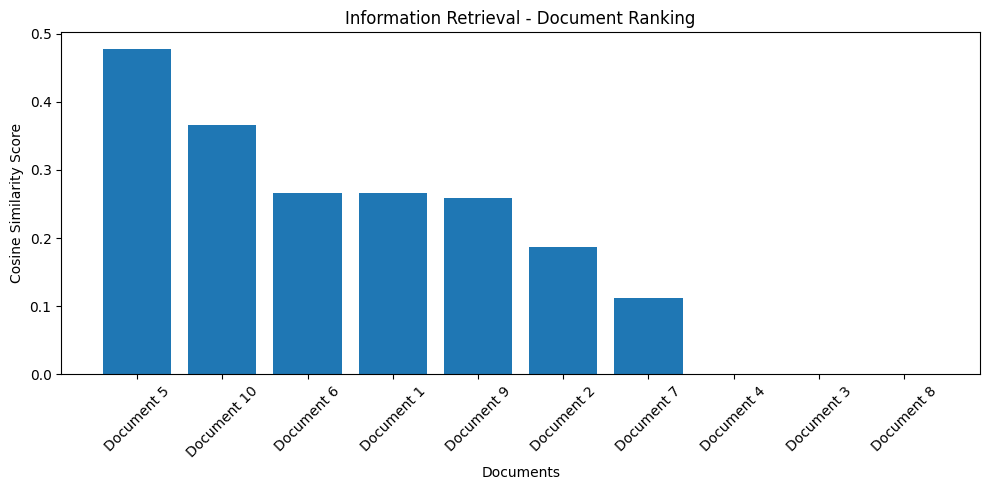


SEARCH RESULTS FOR NEW QUERY:
Query: neural networks and deep learning


,Document,Similarity_Score
0,Neural networks are important in deep learning...,0.770730
1,Deep learning uses neural networks for complex...,0.737365
2,Machine learning enables computers to learn pa...,0.100294
3,Python is widely used for data science and mac...,0.100294
4,Data science combines statistics programming a...,0.097573
5,Natural language processing helps computers un...,0.000000
6,Artificial intelligence is used in robotics an...,0.000000
7,Computer vision enables machines to recognize ...,0.000000
8,Text processing is an important task in natura...,0.000000
9,Robotics uses artificial intelligence to autom...,0.000000



RESULT:
Documents were successfully retrieved and ranked using TF-IDF.

CONCLUSION:
The information retrieval system ranks documents according
to their relevance to the search query using TF-IDF vectors
and cosine similarity.


In [ ]:
# ============================================================
# PRACTICAL 21: INFORMATION RETRIEVAL USING TF-IDF
# Course Outcome: CO2
# ============================================================
# Name: Aditya kumar Singh
# OBJECTIVE:
# To develop an information retrieval system that retrieves and
# ranks relevant documents using TF-IDF and cosine similarity.

# Install required library
!pip -q install scikit-learn

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display

# ------------------------------------------------------------
# 1. DOCUMENT COLLECTION
# ------------------------------------------------------------

documents = [
    "Machine learning enables computers to learn patterns from data.",
    "Deep learning uses neural networks for complex learning tasks.",
    "Natural language processing helps computers understand human language.",
    "Computer vision enables machines to recognize images and objects.",
    "Artificial intelligence is used in robotics and automation.",
    "Python is widely used for data science and machine learning.",
    "Neural networks are important in deep learning applications.",
    "Text processing is an important task in natural language processing.",
    "Data science combines statistics programming and machine learning.",
    "Robotics uses artificial intelligence to automate real world tasks."
]

doc_ids = [f"Document {i}" for i in range(1, len(documents) + 1)]

# ------------------------------------------------------------
# 2. TF-IDF VECTORIZATION
# ------------------------------------------------------------

vectorizer = TfidfVectorizer(stop_words="english")

tfidf_matrix = vectorizer.fit_transform(documents)

print("TF-IDF MATRIX SHAPE:", tfidf_matrix.shape)

# ------------------------------------------------------------
# 3. USER SEARCH QUERY
# ------------------------------------------------------------

query = "machine learning and artificial intelligence"

query_vector = vectorizer.transform([query])

# ------------------------------------------------------------
# 4. CALCULATE DOCUMENT SIMILARITY
# ------------------------------------------------------------

similarity_scores = cosine_similarity(
    query_vector,
    tfidf_matrix
).flatten()

# ------------------------------------------------------------
# 5. RANK DOCUMENTS
# ------------------------------------------------------------

ranking = pd.DataFrame({
    "Document_ID": doc_ids,
    "Document": documents,
    "Similarity_Score": similarity_scores
})

ranking = ranking.sort_values(
    by="Similarity_Score",
    ascending=False
).reset_index(drop=True)

ranking.insert(0, "Rank", range(1, len(ranking) + 1))

print("\nRANKED DOCUMENTS:")
display(ranking)

# ------------------------------------------------------------
# 6. RETRIEVE RELEVANT DOCUMENTS
# ------------------------------------------------------------

threshold = 0.05

retrieved_documents = ranking[
    ranking["Similarity_Score"] > threshold
]

print("\nRETRIEVED DOCUMENTS:")
display(retrieved_documents)

# ------------------------------------------------------------
# 7. VISUALIZE DOCUMENT RANKING
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    ranking["Document_ID"],
    ranking["Similarity_Score"]
)

plt.title("Information Retrieval - Document Ranking")
plt.xlabel("Documents")
plt.ylabel("Cosine Similarity Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. SEARCH WITH A NEW QUERY
# ------------------------------------------------------------

new_query = "neural networks and deep learning"

new_query_vector = vectorizer.transform([new_query])

new_scores = cosine_similarity(
    new_query_vector,
    tfidf_matrix
).flatten()

new_ranking = pd.DataFrame({
    "Document": documents,
    "Similarity_Score": new_scores
}).sort_values(
    by="Similarity_Score",
    ascending=False
).reset_index(drop=True)

print("\nSEARCH RESULTS FOR NEW QUERY:")
print("Query:", new_query)
display(new_ranking)

# ------------------------------------------------------------
# 9. RESULT AND CONCLUSION
# ------------------------------------------------------------

print("\nRESULT:")
print("Documents were successfully retrieved and ranked using TF-IDF.")

print("\nCONCLUSION:")
print("The information retrieval system ranks documents according")
print("to their relevance to the search query using TF-IDF vectors")
print("and cosine similarity.")